# Analysis of experimental data

This notebook documents analysis of experimental data resulting from developed pitch pipelines. This document is focused on analysis and findings. For complete analysis code see ./pitch_analysis.py

## 1. Datasets used

- [ChoraleBricks](https://zenodo.org/records/15081741)

## 2. Metrics

### GPE (Gross Pitch Error)
The proportion of (voiced) frames for which estimated f0 was substantially different from the reference data

### MAE (Mean Absolute Error)
The average absolute error across all frames

In [77]:
import importlib.util
import subprocess
import sys

packages = ["pandas", "matplotlib", "pathlib", "numpy"]

for package in packages:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", package
        ])

from pathlib import Path
import pandas as pd
import pitch_analysis
import matplotlib.pyplot as plt
import os
import re
# reload pitch_analysis to ensure latest code
importlib.reload(pitch_analysis)

<module 'pitch_analysis' from 'c:\\Users\\sotte\\Documents\\Scripts\\00_project\\CSM500-2026-APR_Project\\SawEars_client\\algorithm_development\\src\\main\\python\\pitch_analysis.py'>

Here we load the raw data from experiments conducted in kotlin, including timestamped predictions per dataset per file, but without labelled f0 data.

In [78]:
experiment_data_folder = Path.cwd().parent.parent.parent / "experimental_data"
dataPath = experiment_data_folder / "window_size"
resultsFiles = [path for path in dataPath.iterdir() if path.is_file() and "windowSize" in path.name]

summary_export_name = Path.cwd() / "results" / "effect_of_window_size.csv"

# 3. Window Size
In this section we investigate the impact of window size, that is to say the number of audio samples included in each estimation window. This can be expected to impact accuracy as a larger window means more information is available to the algorithm, however the impact is likely to be non-monotonic as too large a window is likely to include pitch transitions, reducing the specificity of the estimate. We would therefore expect to see an inverted U-shaped relationship where accuracy increases with window up to some threshold beyond which increasing window size has an adverse effect on accuracy.

The relationship between window size and processing time is less intuitive and depends on algorithm and implementation factors, but in general it's hypothesized that window size will be positively correlated with processing time as larger windows will be more computationally expensive. 

## 3.1 data processing
Here we conduct the following steps on the raw experimental data:

1. For each audio file, find the corresponding labelled data
2. Align the estimated timestamps with the labelled data
3. Based on aligned timestamps, compare labelled f0 vs predicted f0 across dataset to calculate metrics

In [81]:
def process_results(file: Path,insert_ws=False):

    # process data
    file_data = pitch_analysis.PitchExperimentData(file)
    processed_data = file_data.process()
    # exclude dynamic wavelet results
    processed_data = processed_data[processed_data["estimator"] != "DynamicWaveletEstimator"]
    # add window size column
    if insert_ws:
        # get window size from filename
        windowSize = int(re.search(r"(\d+)\.csv$", file.name).group(1))
        processed_data.insert(1, "windowSize", windowSize)

    # add instrument column
    processed_data["instrument"] = (
        processed_data["track"]
            .str
            .split("_")
            .str[-1]
            .str
            .removesuffix(".wav")
        )
    summary = (
        processed_data.groupby(["windowSize","estimator", "dataset"], as_index=False)
        .agg({
            "MAE": "mean",
            "GPE": "mean",
            "processing_time_file": "mean"
        })
    )
    return summary

In [82]:
processed_data = [process_results(file,True) for file in resultsFiles]


Aggregate results from different window sizes into a combined dataframe

In [83]:
combined_results = pd.concat(processed_data, ignore_index=True)
combined_results.sort_values(
    by=["estimator", "windowSize"],
    ascending=[True,True]
)
combined_results.to_csv(summary_export_name,index=False)

In [84]:
# read results from csv to prevent having to recalculate everything
window_data = pd.read_csv(summary_export_name)

window_data = window_data.sort_values(
    by=["estimator", "windowSize"],
    ascending=[True,True]
)
window_data

,windowSize,estimator,dataset,MAE,GPE,processing_time_file
8,256,FastYinEstimator,ChoraleBricks,147.582066,24.687282,91.884298
12,512,FastYinEstimator,ChoraleBricks,34.458031,3.811684,92.669421
0,1024,FastYinEstimator,ChoraleBricks,35.774370,4.789031,98.371901
4,2048,FastYinEstimator,ChoraleBricks,40.928155,7.338939,104.148760
9,256,McLeodEstimator,ChoraleBricks,29.370076,3.495522,391.190083
13,512,McLeodEstimator,ChoraleBricks,52.529142,3.697447,729.917355
1,1024,McLeodEstimator,ChoraleBricks,14.162969,2.796185,1429.892562
5,2048,McLeodEstimator,ChoraleBricks,19.050056,4.631644,2801.181818
10,256,RTSwipeEstimator,ChoraleBricks,36.547357,10.624824,7276.578512
14,512,RTSwipeEstimator,ChoraleBricks,37.389065,10.945634,3571.429752


## 3.2 Results by estimator by window size

In [93]:
import matplotlib.pyplot as plt

# here we define a custom function to show the effect of window size on different metrics

def window_size_chart(
    df: pd.DataFrame,
    metric: str,
    x_label: str,
    y_label: str
):
    chart_data = df[["windowSize","estimator",metric]].pivot(
        index="estimator",
        columns="windowSize",
        values=metric
    )
    ax = chart_data.plot(
        kind="bar"
        )
    ax.set_title(None)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    plt.tight_layout()
    plt.show()


### Chart 1 - Effect of window size on MAE (mean absolute error)

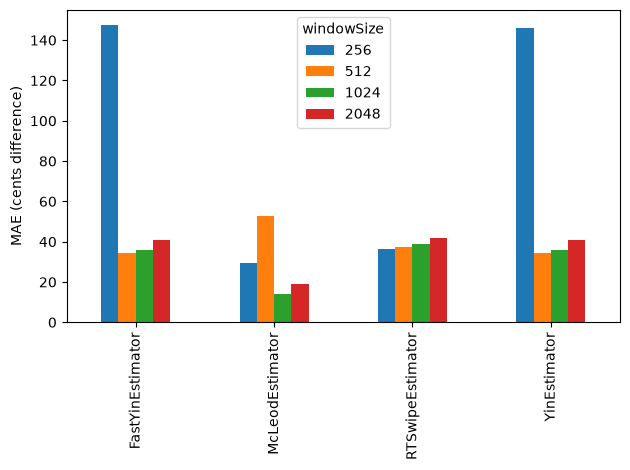

In [86]:
window_size_chart(
    window_data,
    metric="MAE",
    x_label=None,
    y_label="MAE (cents difference)"
    )

### Chart 2 - Effect of window size on Gross Pitch Error (GPE)

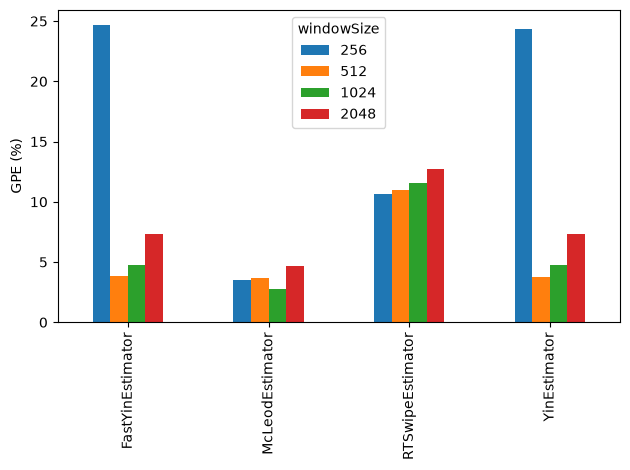

In [87]:
window_size_chart(
    window_data,
    metric="GPE",
    x_label=None,
    y_label="GPE (%)"
    )

### Chart 3 - Effect of window size on processing time

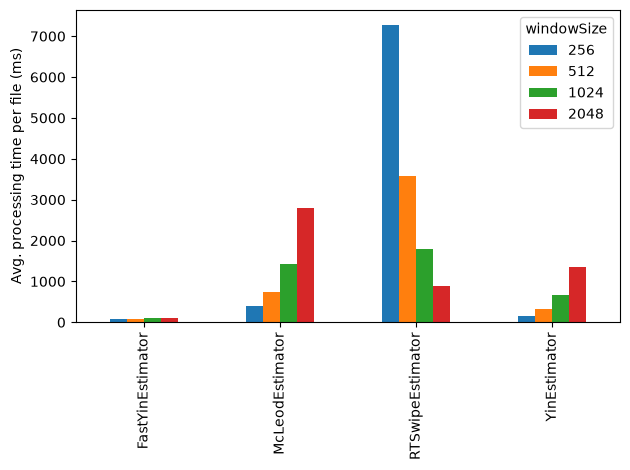

In [88]:
window_size_chart(
    window_data,
    metric="processing_time_file",
    x_label=None,
    y_label="Avg. processing time per file (ms)"
    )

# 3.2.1. False negatives
The  above GPE and MAE results only consider positive estimates (frames where the algorithm made an estimate), and exclude false negatives (frames where a pitch should have been reported but the algorithm made no estimate). In this section we examine the proportion of false negative voicing errors per estimator per window size.

In [89]:
def process_unvoiced_results(file: Path):

    # process data
    file_data = pitch_analysis.PitchExperimentData(file)
    file_data = file_data.process()
    # exclude dynamic wavelet results
    processed_data = file_data[file_data["estimator"] != "DynamicWaveletEstimator"]
    # add window size column
    # get window size from filename
    windowSize = int(re.search(r"(\d+)\.csv$", file.name).group(1))
    processed_data.insert(1, "windowSize", windowSize)
    return processed_data

In [90]:
unvoiced_results = [process_unvoiced_results(file) for file in resultsFiles]

In [91]:
df = unvoiced_results[0]
df.head()

,dataset,windowSize,track,estimator,MAE,GPE,false_negatives,processing_time_file,instrument
0,ChoraleBricks,1024,Anonymous_AusMeinesHerzensGrunde__01_as.wav,RTSwipeEstimator,49.859420,12.621015,0.000000,2469.0,as
1,ChoraleBricks,1024,Anonymous_AusMeinesHerzensGrunde__01_as.wav,FastYinEstimator,17.898144,4.062240,0.006987,137.0,as
2,ChoraleBricks,1024,Anonymous_AusMeinesHerzensGrunde__01_as.wav,YinEstimator,19.191815,4.115763,0.005772,940.0,as
4,ChoraleBricks,1024,Anonymous_AusMeinesHerzensGrunde__01_as.wav,McLeodEstimator,20.118523,3.235048,0.011239,2025.0,as
5,ChoraleBricks,1024,Anonymous_AusMeinesHerzensGrunde__01_cl.wav,RTSwipeEstimator,44.456884,10.809207,0.000000,2522.0,cl


### Chart 4 - False negative predictions by estimator by window size
As this chart shows, some models were substantially more likely to report false negatives. For YIN and related algorithms this is likely because at small window sizes the estimator did not have access to sufficient data to make a prediction. 

These differences aside, the absolute proportion of false negative predictions is negligible across all estimators so excluding these frames from averages is unlikely to contribute significantly to any of the results discussed above.

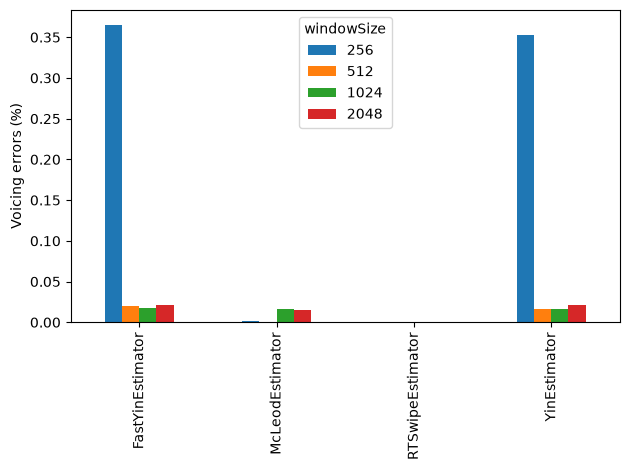

In [107]:
df2: pd.DataFrame = pd.concat(unvoiced_results,ignore_index=True)
df2 = df2[["dataset","windowSize","estimator","false_negatives"]].copy().groupby(["windowSize","estimator","dataset"],as_index=False).agg(
    {
        "false_negatives": "mean",
    }
)
window_size_chart(
    df2,
    metric="false_negatives",
    x_label=None,
    y_label="Voicing errors (%)"
)

## Analysis
- McLeod had the lowest GPE and MAE, but moderately higher processing time, making it less suitable for real time analysis. It also requires a larger window size to perform optimally, which will further impact real-time processing latency as capture time is proportional to window size. This latter effect may be more significant to overall perceived latency than processing time.
- Yin and Fast Yin had comparable accuracy but FastYin has dramatically faster processing.
- RTSwipe performed poorly on both accuracy and latency, and is not supported by this data. This could potentially be due to defects in the implementation.

# Recommendations
Based on these data, the McLeod algorithm is the clear winner on accuracy, while the Fast YIN algorithm, specifically its FastYin implementation, is the clear winner on speed at the expense of moderately higher MAE. Either FastYin or McLeod could therefore be considered the optimal choice depending on the priority given to speed vs. accuracy. 

It's proposed here that a slight decrease in accuracy is preferable to noticeable latency so it is recommended to implement both estiamtors and evaluate the extent to which algorithm choice contributes to latency in the application context.